# Data Analysis Laboratory 02: Graz Weather Data
Fink Lucas, ESE26

AI Decleration: This script was created with the help of Antigravity (Orchestrator: Gemini 4 Neon, November 2026). AI used to correct and beautify data plots.


## Prerequisites

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
%matplotlib widget

## Assignment 2

### Import Data

In [22]:
data = pd.read_csv("data/NTC.csv", sep=",")

The data shows a cooling process recorded with two separate temperature sensors, one Pt100 (direct T-reading) and an 4.7kOhm NTC (resistance measurement only)

### Data Inspection

In [23]:
display(data.describe())
print(f"Size: {data.size} values")
print(f"Shape: {data.shape} (rows, columns)")
print(f"Columns: {data.columns} ")

,time[ns],T_Pt100[C],R_NTC[Ohm]
count,2.762800e+04,27628.000000,27628.000000
mean,1.252404e+14,-29.870318,193089.717407
std,1.595133e+12,35.295784,243740.306137
min,1.224777e+14,-74.383290,4363.876500
25%,1.238590e+14,-65.118676,8140.860875
50%,1.252404e+14,-35.527489,53365.482000
75%,1.266217e+14,4.273021,347137.662500
max,1.280031e+14,25.558437,812936.500000


Size: 110512 values
Shape: (27628, 4) (rows, columns)
Columns: Index(['timestamp', 'time[ns]', 'T_Pt100[C]', 'R_NTC[Ohm]'], dtype='str') 


### Plotting the PT100 Temperature over Time

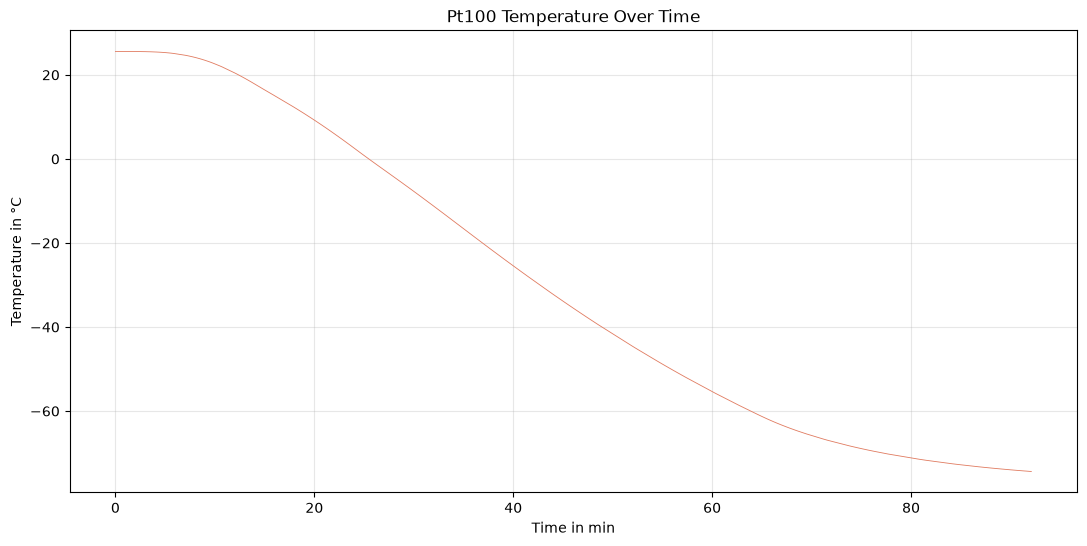

In [24]:
time_min = (data["time[ns]"] - data["time[ns]"].iloc[0]) / (1e9 * 60)

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(time_min, data["T_Pt100[C]"], color="#e07a5f", linewidth=0.6)

ax.set_title("Pt100 Temperature Over Time")
ax.set_xlabel("Time in min")
ax.set_ylabel("Temperature in °C")
ax.grid(True, alpha=0.3)

plt.show()

### Define the Derivative of the Pt100 Temperature & Plot it

**Instantaneous rate of temperature change ($^\circ\text{C/s}$):**

$$\frac{dT}{dt} = \lim_{\Delta t \to 0} \frac{T(t + \Delta t) - T(t)}{\Delta t}$$



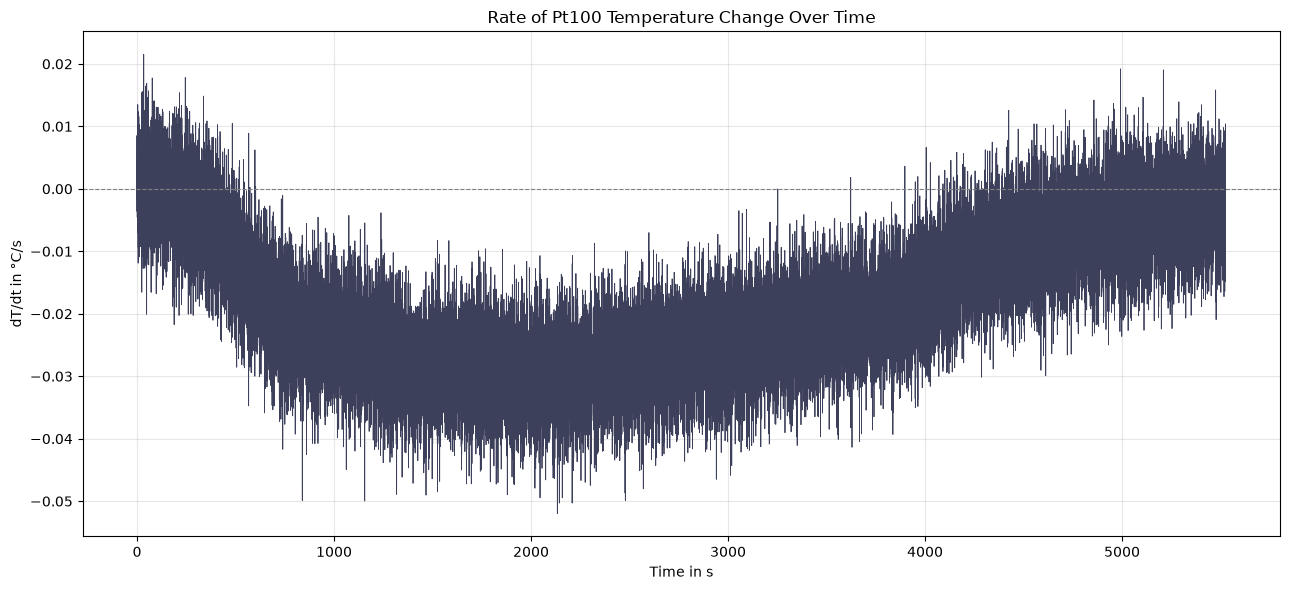

In [33]:
import numpy as np

t_s = data["time[ns]"].to_numpy() * 1e-9
T = data["T_Pt100[C]"].to_numpy()
dT_dt = np.gradient(T, t_s) # Derivative computed with gradient function form numpy

fig, ax1 = plt.subplots(figsize=(13, 6))

ax1.plot(t_s - t_s[0], dT_dt, color="#3d405b", linewidth=0.6)
ax1.axhline(0, color="gray", ls="--", lw=0.8)
ax1.set_title("Rate of Pt100 Temperature Change Over Time")
ax1.set_xlabel("Time in s")
ax1.set_ylabel("dT/dt in °C/s")
ax1.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## state-space

## compute NTC temperature

## correlate data

## state-space take 2